# Отбор признаков для бустинга: от 100 к 30

Ноутбук повторяет маршрут отбора из лекции «Как делают бустинги: промышленная практика»
на учебном датасете `data/scoring_1000x100.csv` (1000 строк, 100 признаков, таргет — дефолт).

Маршрут:

| Шаг | Что делаем | Зачем |
|---|---|---|
| 0 | Модель на всех признаках | точка отсчёта |
| 1 | Убираем признаки с нулевой важностью | модель их ни разу не использовала |
| 2 | PSI и ручной бан красных | нестабильные признаки вытесняют хорошие и ломают модель на новых данных |
| 3 | Backward по важности пачками | хвост по важности почти ничего не стоит |
| 4 | Корреляции | из пары похожих оставляем ту, без которой Gini падает сильнее |
| 5 | Backward по Gini до 30 | убираем по одному тот, без которого Gini на val максимален |

Функции ниже — упрощённые версии функций фреймворка: та же логика, без Spark, логов в Excel
и контрольных точек.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from joblib import Parallel, delayed

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 120)

TARGET, CLIENT, DATE = 'target', 'client_id', 'report_month'
SEED = 888

## Данные и разбиение

* **OOT** (out-of-time) — последние три месяца, октябрь–декабрь 2025. На нём ничего не выбираем,
  он показывает, что будет с моделью на новых данных.
* **test** — 20 % клиентов из остальных месяцев. Делим по клиентам: у клиента бывает несколько строк,
  и клиент целиком либо в train, либо в test.
* **train** делим на 5 фолдов тоже по клиентам (`StratifiedGroupKFold`): учимся на четырёх,
  меряем Gini на пятом — это **val**. Все решения отбора принимаем по Gini на val.

In [2]:
df = pd.read_csv('data/scoring_1000x100.csv')
features_all = [c for c in df.columns if c not in (TARGET, CLIENT, DATE)]
print(df.shape, '| признаков:', len(features_all), '| доля дефолтов:', round(df[TARGET].mean(), 3))

OOT_FROM = '2025-10'
df['sample'] = np.where(df[DATE] >= OOT_FROM, 'oot', 'train')
dev_clients = df.loc[df['sample'] == 'train', CLIENT].unique()
rng = np.random.default_rng(SEED)
test_clients = rng.choice(dev_clients, size=int(0.2 * len(dev_clients)), replace=False)
df.loc[(df['sample'] == 'train') & df[CLIENT].isin(test_clients), 'sample'] = 'test'

train_df = df[df['sample'] == 'train'].reset_index(drop=True)
test_df = df[df['sample'] == 'test'].reset_index(drop=True)
oot_df = df[df['sample'] == 'oot'].reset_index(drop=True)

folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
             .split(train_df, train_df[TARGET], groups=train_df[CLIENT]))

df.groupby('sample')[TARGET].agg(rows='size', bad_rate='mean').round(3)

(1000, 103) | признаков: 100 | доля дефолтов: 0.272


,rows,bad_rate
sample,,
oot,240,0.246
test,153,0.248
train,607,0.288


## Функции

`train_cv` — упрощённая `train_and_evaluate_catboost_model_all_dataset`: пять моделей на фолдах.
Gini train и val — среднее по пяти фолдам; для test и OOT прогнозы пяти моделей усредняем и считаем
один Gini. Gini = 2·AUC − 1, в пунктах (0–100). Важность (FI) усредняем по пяти моделям.

`check_many` — упрощённая `feature_checker4`: обучает много наборов признаков параллельно,
каждая модель на своём ядре (`thread_count=1`).

In [3]:
def gini(y, p):
    return 100 * (2 * roc_auc_score(y, p) - 1)


def train_cv(features, iterations=300, FI=False):
    params = dict(iterations=iterations, loss_function='Logloss', eval_metric='AUC',
                  random_state=SEED, thread_count=1, od_type='Iter', od_wait=50, verbose=False)
    tr_g, val_g, fi = [], [], np.zeros(len(features))
    test_p, oot_p = np.zeros(len(test_df)), np.zeros(len(oot_df))
    X, y = train_df[features], train_df[TARGET]
    for tr, va in folds:
        m = CatBoostClassifier(**params)
        m.fit(X.iloc[tr], y.iloc[tr], eval_set=(X.iloc[va], y.iloc[va]), use_best_model=True)
        tr_g.append(gini(y.iloc[tr], m.predict_proba(X.iloc[tr])[:, 1]))
        val_g.append(gini(y.iloc[va], m.predict_proba(X.iloc[va])[:, 1]))
        test_p += m.predict_proba(test_df[features])[:, 1] / len(folds)
        oot_p += m.predict_proba(oot_df[features])[:, 1] / len(folds)
        fi += m.get_feature_importance() / len(folds)
    res = dict(n=len(features), train=np.mean(tr_g), val=np.mean(val_g),
               test=gini(test_df[TARGET], test_p), oot=gini(oot_df[TARGET], oot_p))
    if FI:
        res['FI'] = pd.Series(fi, index=features).sort_values(ascending=False)
    return res


def check_many(feature_sets, iterations=100):
    return Parallel(n_jobs=-1)(delayed(train_cv)(fs, iterations) for fs in feature_sets)


def drop_one_each(current, candidates, iterations=100):
    # Для каждого кандидата: Gini без него. Сверху — тот, кого меньше всего жалко.
    res = check_many([[f for f in current if f != c] for c in candidates], iterations)
    out = pd.DataFrame([{k: r[k] for k in ('train', 'val', 'test', 'oot')} for r in res])
    out.insert(0, 'без признака', candidates)
    return out.sort_values('val', ascending=False).reset_index(drop=True)


LOG = []
def log_step(step, res):
    LOG.append({'шаг': step, 'признаков': res['n'],
                **{k: round(res[k], 1) for k in ('train', 'val', 'test', 'oot')}})
    return pd.DataFrame(LOG).set_index('шаг')

## Шаг 0. Модель на всех 100 признаках

In [4]:
current = features_all.copy()
res = train_cv(current, iterations=1000, FI=True)
log_step('0. Все признаки', res)

,признаков,train,val,test,oot
шаг,,,,,
0. Все признаки,100,94.0,60.7,63.3,36.4


## Шаг 1. Убираем признаки с нулевой важностью

Пустые и константные признаки модель не может использовать: их важность ровно ноль.

In [5]:
fi = res['FI']
zero_fi = fi[fi == 0].index.tolist()
print('Нулевая важность:', zero_fi)
current = [f for f in current if f not in zero_fi]
res = train_cv(current, iterations=1000, FI=True)
log_step('1. Без нулевой FI', res)

Нулевая важность: ['currency_code', 'old_limit_2019', 'branch_closed_flag', 'kyc_version', 'legacy_score_v1']


,признаков,train,val,test,oot
шаг,,,,,
0. Все признаки,100,94.0,60.7,63.3,36.4
1. Без нулевой FI,95,91.9,63.0,66.8,37.9


## Шаг 2. PSI и ручной бан красных

PSI (Population Stability Index) показывает, насколько распределение признака в периоде
отличается от базы: PSI = Σ (q − p) · ln(q / p) по бинам, p — доли в базе, q — в периоде.
База — все периоды до OOT, 10 квантильных бинов по базе, пропуски — отдельный бин.

Уровни: **зелёный** ≤ 0,1, **жёлтый** 0,1–0,25, **красный** > 0,25.

Строк всего 1000, в месяце около 80 — на таком объёме PSI по месяцам шумит. Поэтому считаем
по кварталам: в квартале около 250 строк.

In [6]:
def psi(base, cur, n_bins=10):
    # Упрощённая fast_psi: квантильные бины по базе, пропуски — отдельный бин.
    base, cur = np.asarray(base, float), np.asarray(cur, float)
    if np.isnan(base).all():
        return 0.0
    edges = np.unique(np.nanquantile(base, np.linspace(0, 1, n_bins + 1)))[1:-1]
    def shares(x):
        nan = np.isnan(x)
        cnt = np.bincount(np.searchsorted(edges, x[~nan], side='right'), minlength=len(edges) + 1)
        return np.append(cnt, nan.sum()) / len(x)
    p, q = shares(base), shares(cur)
    ok = (p > 0) & (q > 0)
    return float(np.sum((q[ok] - p[ok]) * np.log(q[ok] / p[ok])))


def psi_table(data, cols):
    period = pd.PeriodIndex(data[DATE], freq='M').asfreq('Q').astype(str)
    base = data[data['sample'] != 'oot']
    return pd.DataFrame({q: [psi(base[c], data.loc[period == q, c]) for c in cols]
                         for q in sorted(period.unique())}, index=cols)


def color_psi(v):
    return 'color: red; font-weight: bold' if v > 0.25 else 'color: orange' if v > 0.1 else 'color: green'


psi_df = psi_table(df, current)
fi = res['FI']
show = psi_df.loc[fi.index].assign(FI=fi.round(2), FI_rank=np.arange(len(fi)))
show.head(25).style.format('{:.2f}', subset=psi_df.columns).map(color_psi, subset=psi_df.columns)

,2025Q1,2025Q2,2025Q3,2025Q4,FI,FI_rank
night_txn_share_1m,0.02,0.02,0.01,0.80,7.440000,0
dpd_max_12m,0.02,0.02,0.01,0.01,5.410000,1
hotline_calls_30d,0.01,0.01,0.00,0.50,5.150000,2
crypto_transfers_1m,0.03,0.02,0.02,0.73,4.990000,3
microloan_apps_90d,0.01,0.00,0.00,0.60,4.470000,4
dpd_max_6m,0.03,0.01,0.02,0.05,3.590000,5
cash_withdrawal_share_1m,0.02,0.01,0.01,0.55,3.130000,6
salary_inflow_1m,0.01,0.02,0.02,0.08,2.700000,7
bki_score_prev,0.08,0.02,0.02,0.07,2.650000,8
payment_to_balance,0.03,0.02,0.03,0.06,2.440000,9


Таблица отсортирована по важности. Почти все красные признаки — в самом верху: модель держится
за них сильнее всего. В последнем квартале (это OOT) их распределение уехало.
Два красных признака стоят внизу по важности — они нестабильны и при этом бесполезны.

In [7]:
red = psi_df.index[(psi_df > 0.25).any(axis=1)].tolist()
print('Красные:', red)
psi_df.loc[red].round(2).assign(FI_rank=[fi.index.get_loc(f) for f in red]).sort_values('FI_rank')

Красные: ['app_version_code', 'cash_withdrawal_share_1m', 'crypto_transfers_1m', 'gambling_spend_3m', 'hotline_calls_30d', 'microloan_apps_90d', 'night_txn_share_1m', 'promo_offer_cnt_1m']


,2025Q1,2025Q2,2025Q3,2025Q4,FI_rank
night_txn_share_1m,0.02,0.02,0.01,0.80,0
hotline_calls_30d,0.01,0.01,0.00,0.50,2
crypto_transfers_1m,0.03,0.02,0.02,0.73,3
microloan_apps_90d,0.01,0.00,0.00,0.60,4
cash_withdrawal_share_1m,0.02,0.01,0.01,0.55,6
gambling_spend_3m,0.04,0.02,0.02,0.81,15
app_version_code,0.04,0.03,0.02,2.03,66
promo_offer_cnt_1m,0.01,0.00,0.01,2.77,82


Баним их руками, не разбираясь, почему они сломаны. Смотрим, что стало с Gini:

In [8]:
current = [f for f in current if f not in red]
res = train_cv(current, iterations=1000, FI=True)
log_step('2. Бан красных по PSI', res)

,признаков,train,val,test,oot
шаг,,,,,
0. Все признаки,100,94.0,60.7,63.3,36.4
1. Без нулевой FI,95,91.9,63.0,66.8,37.9
2. Бан красных по PSI,87,90.5,50.4,48.6,46.2


Gini на val упал — это цена стабильности. Зато на OOT модель стала лучше: красные признаки
на новых данных больше не работают, а модель на них опиралась вместо хороших.
Если бы мы оставили их до конца отбора, на шагах ниже они вытеснили бы стабильные признаки.

## Шаг 3. Backward по важности пачками

Обучили модель → посмотрели важность → выкинули хвост → повторили. Чем меньше осталось признаков,
тем меньше пачка: пока больше 60 — по 10, дальше по 5. Останавливаемся на 45.
После каждого шага важность считаем заново.

In [9]:
def backward_fi(current, n_stop=45):
    while len(current) > n_stop:
        r = train_cv(current, iterations=300, FI=True)
        batch = 10 if len(current) > 60 else 5
        batch = min(batch, len(current) - n_stop)
        print(f"{len(current):3d} признаков | val {r['val']:.1f} | oot {r['oot']:.1f} | выкидываем {batch}: "
              + ', '.join(r['FI'].index[-batch:]))
        current = r['FI'].index[:-batch].tolist()
    return current


current = backward_fi(current, n_stop=45)
res = train_cv(current, iterations=1000)
log_step('3. Backward по FI', res)

 87 признаков | val 52.0 | oot 44.2 | выкидываем 10: txn_sum_cafe_1m, inquiries_bki_90d, client_age, txn_sum_travel_1m, new_loans_bki_6m, phone_change_cnt_5y, transfers_out_cnt_1m, bonus_points_balance, txn_cnt_pharmacy_1m, investment_flag
 77 признаков | val 51.5 | oot 49.2 | выкидываем 10: txn_cnt_electronics_1m, auto_payments_cnt, txn_cnt_clothes_1m, atm_visits_3m, txn_sum_fuel_1m, txn_sum_online_3m, txn_sum_travel_3m, region_avg_salary, distinct_mcc_3m, insurance_products_cnt
 67 признаков | val 51.9 | oot 47.1 | выкидываем 10: txn_sum_pharmacy_1m, txn_sum_electronics_1m, foreign_txn_share, family_members_cnt, txn_sum_pharmacy_3m, overdraft_days_3m, education_code, address_change_cnt_5y, inquiries_bki_30d, txn_cnt_online_1m
 57 признаков | val 52.3 | oot 48.5 | выкидываем 5: transfers_in_cnt_1m, deposit_sum, txn_sum_utilities_1m, dependents_cnt, marital_code
 52 признаков | val 47.8 | oot 47.3 | выкидываем 5: max_ticket_3m, salary_inflow_3m, distinct_merchants_3m, cashback_sum_3m, 

,признаков,train,val,test,oot
шаг,,,,,
0. Все признаки,100,94.0,60.7,63.3,36.4
1. Без нулевой FI,95,91.9,63.0,66.8,37.9
2. Бан красных по PSI,87,90.5,50.4,48.6,46.2
3. Backward по FI,45,97.4,50.1,53.7,44.4


## Шаг 4. Корреляции

В каждой паре с корреляцией выше 0,7 пробуем убрать то один признак, то другой. Выкидываем тот,
без которого Gini на val выше (то есть теряем меньше всего). Повторяем, пока пары не кончатся.

In [10]:
CORR = 0.7
corr = train_df[current].corr().abs()
pairs = (corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack()
         .rename('corr').reset_index().query('corr > @CORR').sort_values('corr', ascending=False))
pairs.round(2)

,level_0,level_1,corr
961,txn_sum_food_3m,txn_sum_food_1m,0.99
634,txn_sum_taxi_3m,txn_sum_taxi_1m,0.99
484,txn_sum_clothes_1m,txn_sum_clothes_3m,0.99
363,utilization_cc,utilization_cc_max_6m,0.96
0,dpd_max_6m,dpd_max_12m,0.96
92,bki_score,bki_score_prev,0.94
956,txn_sum_food_3m,txn_cnt_food_1m,0.77
979,txn_cnt_food_1m,txn_sum_food_1m,0.76
919,txn_cnt_taxi_1m,txn_sum_taxi_1m,0.76
626,txn_sum_taxi_3m,txn_cnt_taxi_1m,0.76


In [11]:
while len(pairs):
    cand = sorted(set(pairs['level_0']) | set(pairs['level_1']))
    duel = drop_one_each(current, cand)
    worst = duel.loc[0, 'без признака']
    print(f"убираем {worst:<24} val без него {duel.loc[0, 'val']:.1f}")
    current.remove(worst)
    pairs = pairs[(pairs['level_0'] != worst) & (pairs['level_1'] != worst)]

res = train_cv(current, iterations=1000)
log_step('4. Корреляции', res)

убираем utilization_cc_max_6m    val без него 53.2
убираем dpd_max_6m               val без него 54.2
убираем txn_sum_food_1m          val без него 54.2
убираем bki_score_prev           val без него 54.0
убираем txn_sum_fuel_3m          val без него 52.2
убираем txn_cnt_food_1m          val без него 56.1
убираем txn_sum_clothes_3m       val без него 52.6
убираем txn_cnt_taxi_1m          val без него 50.9
убираем txn_sum_taxi_1m          val без него 52.8


,признаков,train,val,test,oot
шаг,,,,,
0. Все признаки,100,94.0,60.7,63.3,36.4
1. Без нулевой FI,95,91.9,63.0,66.8,37.9
2. Бан красных по PSI,87,90.5,50.4,48.6,46.2
3. Backward по FI,45,97.4,50.1,53.7,44.4
4. Корреляции,36,98.4,53.9,58.3,51.7


## Шаг 5. Backward по Gini до 30

На каждом раунде убираем по одному признаку и обучаем модель без него. Выкидываем тот,
без которого Gini на val максимален — то есть потеря минимальна.

In [12]:
N_FINAL = 30
rounds = []
while len(current) > N_FINAL:
    duel = drop_one_each(current, current)
    worst = duel.loc[0, 'без признака']
    rounds.append(duel.loc[0])
    current.remove(worst)
    print(f"{len(current) + 1} → {len(current)}: убираем {worst:<24} val без него {duel.loc[0, 'val']:.1f}")

duel.head(10).round(1)  # последний раунд: кого меньше всего жалко

36 → 35: убираем txn_sum_online_1m        val без него 56.5
35 → 34: убираем sms_open_rate            val без него 54.9
34 → 33: убираем contactless_share        val без него 55.3
33 → 32: убираем payroll_project_flag     val без него 54.0
32 → 31: убираем credit_limit_total       val без него 55.2
31 → 30: убираем weekend_txn_share        val без него 52.4


,без признака,train,val,test,oot
0,weekend_txn_share,97.7,52.4,51.9,49.7
1,txn_sum_cafe_3m,99.7,52.3,54.6,48.7
2,work_experience_years,98.7,52.2,54.4,46.9
3,txn_sum_electronics_3m,98.5,52.1,55.3,46.0
4,card_cnt_active,98.1,51.5,54.6,49.0
5,region_unemployment,96.6,51.4,49.1,49.9
6,salary_inflow_1m,97.6,51.3,54.2,49.7
7,mobile_app_logins_1m,99.6,50.7,56.2,48.5
8,prev_delinq_cnt_24m,97.6,50.6,58.3,50.1
9,avg_ticket_1m,96.5,50.5,53.3,45.4


In [13]:
res = train_cv(current, iterations=1000, FI=True)
log_step('5. Backward по Gini', res)

,признаков,train,val,test,oot
шаг,,,,,
0. Все признаки,100,94.0,60.7,63.3,36.4
1. Без нулевой FI,95,91.9,63.0,66.8,37.9
2. Бан красных по PSI,87,90.5,50.4,48.6,46.2
3. Backward по FI,45,97.4,50.1,53.7,44.4
4. Корреляции,36,98.4,53.9,58.3,51.7
5. Backward по Gini,30,92.5,52.1,54.4,48.8


## Итог

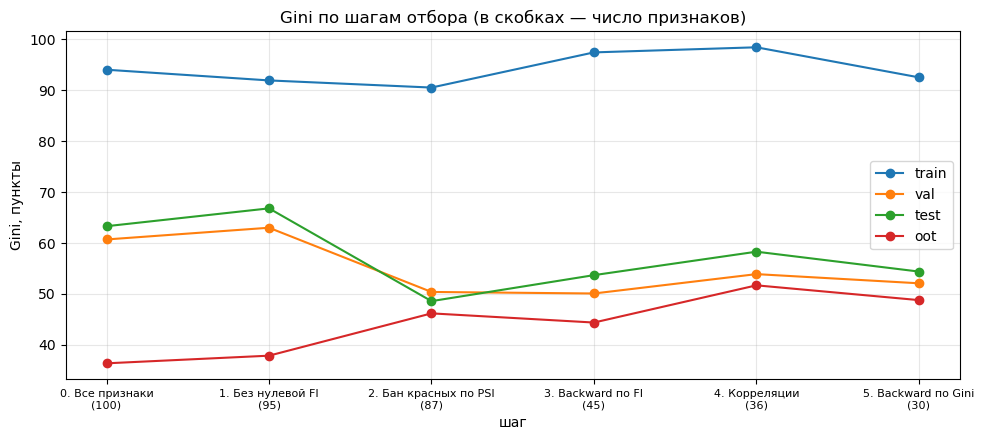

,признаков,train,val,test,oot
шаг,,,,,
0. Все признаки,100,94.0,60.7,63.3,36.4
1. Без нулевой FI,95,91.9,63.0,66.8,37.9
2. Бан красных по PSI,87,90.5,50.4,48.6,46.2
3. Backward по FI,45,97.4,50.1,53.7,44.4
4. Корреляции,36,98.4,53.9,58.3,51.7
5. Backward по Gini,30,92.5,52.1,54.4,48.8


In [14]:
log = pd.DataFrame(LOG).set_index('шаг')
ax = log[['train', 'val', 'test', 'oot']].plot(marker='o', figsize=(10, 4.5))
ax.set_xticks(range(len(log)))
ax.set_xticklabels([f"{s}\n({n})" for s, n in zip(log.index, log['признаков'])], fontsize=8)
ax.set_ylabel('Gini, пункты')
ax.set_title('Gini по шагам отбора (в скобках — число признаков)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
log

In [15]:
final = res['FI'].index.tolist()
print(len(final), 'признаков:')
res['FI'].round(2).to_frame('FI')

30 признаков:


,FI
dpd_max_12m,15.46
bki_score,7.88
payment_to_balance,5.87
utilization_cc,5.32
prev_delinq_cnt_24m,4.57
salary_inflow_1m,4.51
push_click_rate,4.34
reissue_cnt_24m,4.12
dpd_cnt_12m,3.97
debt_to_income,3.74


Последняя проверка: PSI отобранных признаков и PSI самого прогноза модели (строка `pred`).

In [16]:
models = []
X, y = train_df[final], train_df[TARGET]
for tr, va in folds:
    m = CatBoostClassifier(iterations=1000, random_state=SEED, od_type='Iter', od_wait=50,
                           eval_metric='AUC', verbose=False, thread_count=-1)
    m.fit(X.iloc[tr], y.iloc[tr], eval_set=(X.iloc[va], y.iloc[va]), use_best_model=True)
    models.append(m)
df['pred'] = np.mean([m.predict_proba(df[final])[:, 1] for m in models], axis=0)

final_psi = psi_table(df, final + ['pred'])
final_psi.style.format('{:.2f}').map(color_psi)

,2025Q1,2025Q2,2025Q3,2025Q4
dpd_max_12m,0.02,0.02,0.01,0.01
bki_score,0.04,0.01,0.02,0.06
payment_to_balance,0.03,0.02,0.03,0.06
utilization_cc,0.03,0.03,0.02,0.06
prev_delinq_cnt_24m,0.00,0.02,0.02,0.02
salary_inflow_1m,0.01,0.02,0.02,0.08
push_click_rate,0.02,0.03,0.01,0.08
reissue_cnt_24m,0.02,0.00,0.01,0.01
dpd_cnt_12m,0.00,0.00,0.00,0.02
debt_to_income,0.01,0.04,0.04,0.01


## Выводы

* До бана красных Gini на val выглядит отлично, а на OOT модель проваливается: она опирается
  на признаки, которые на новых данных сломались.
* Бан красных стоит много пунктов на val — это цена стабильности. Зато OOT вырастает,
  и дальше отбор идёт уже на стабильных признаках.
* Остальные шаги сокращают признаки втрое почти без потерь.
* Строк всего 1000, поэтому Gini шумит на несколько пунктов от шага к шагу,
  а в итоговые 30 попадают и шумовые признаки. На реальных выборках в сотни тысяч строк
  тот же маршрут работает заметно чище.

In [17]:
pd.Series(final).to_csv('selected_30_features.csv', index=False, header=['feature'])
print('Сохранено: selected_30_features.csv')

Сохранено: selected_30_features.csv
